Data loaded into memory successfully.

 1. SHAPE 
Rows: 4601 | Columns: 58

 2. MISSING VALUES 
Total missing values: 0

 3. COLUMNS 
['word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d', 'word_freq_our', 'word_freq_over', 'word_freq_remove', 'word_freq_internet', 'word_freq_order', 'word_freq_mail', 'word_freq_receive', 'word_freq_will', 'word_freq_people', 'word_freq_report', 'word_freq_addresses', 'word_freq_free', 'word_freq_business', 'word_freq_email', 'word_freq_you', 'word_freq_credit', 'word_freq_your', 'word_freq_font', 'word_freq_000', 'word_freq_money', 'word_freq_hp', 'word_freq_hpl', 'word_freq_george', 'word_freq_650', 'word_freq_lab', 'word_freq_labs', 'word_freq_telnet', 'word_freq_857', 'word_freq_data', 'word_freq_415', 'word_freq_85', 'word_freq_technology', 'word_freq_1999', 'word_freq_parts', 'word_freq_pm', 'word_freq_direct', 'word_freq_cs', 'word_freq_meeting', 'word_freq_original', 'word_freq_project', 'word_freq_re', 'word_freq_edu', 'word_

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_parenthesis,char_freq_bracket,char_freq_exclamation,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1



 6. TARGET DISTRIBUTION 
Proportion of spams: 39.40%


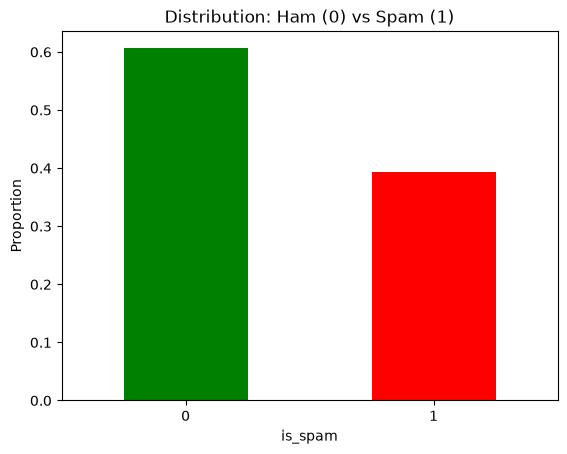

In [2]:
import sys
sys.path.append("../src")

from spamjam.data import DatasetLoader
import matplotlib.pyplot as plt
import pandas as pd

#loading
loader = DatasetLoader(config_path="../config.yaml")
df = loader.load_data()

print("\n 1. SHAPE ")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

print("\n 2. MISSING VALUES ")
# Count the missing values first
total_missing = df.isnull().sum().sum()
print(f"Total missing values: {total_missing}")
if total_missing > 0:
    print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n 3. COLUMNS ")
print(df.columns.tolist())

print("\n 4. DATA TYPES ")
print(df.dtypes)

print("\n 5. HEAD ")
display(df.head())

# 6. Plot for the report
print("\n 6. TARGET DISTRIBUTION ")
y = df['is_spam']
print(f"Proportion of spams: {y.mean():.2%}")

y.value_counts(normalize=True).plot(kind="bar", color=["green", "red"])
plt.title("Distribution: Ham (0) vs Spam (1)")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.show()

In [3]:
#Clean
df_clean = loader.remove_duplicates(df)

#Split and save to data/processed/sb_train.csv and sb_test.csv
train_df, test_df = loader.split_and_save(df_clean)

# 3. Verify the shapes and proportions
print("\n SPLIT VERIFICATION ")
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Train spam ratio: {train_df['is_spam'].mean():.2%}")
print(f"Test spam ratio: {test_df['is_spam'].mean():.2%}")


 SPLIT VERIFICATION 
Train shape: (3368, 58)
Test shape: (842, 58)
Train spam ratio: 39.88%
Test spam ratio: 39.90%
